# Л2 — Сегментація й пошук закономірностей

Коли дані зібрано й очищено, з них починають видобувати знання. Універсального порядку тут немає: метод обирають під питання, на яке шукають відповідь.

Ноутбук нижче показує кілька поширених методів на одних даних і пастки, через які висновок буває хибним.

| Питання | Метод | Кроки |
|---|---|---|
| На які групи діляться абоненти? | кластеризація: k-середні, метод Варда | 2, 4–7 |
| Які показники змінюються разом? | головні компоненти (PCA) | 3 |
| Як наочно показати, хто на кого схожий? | карта Кохонена | 8 |
| Які події трапляються разом? | асоціативні правила | 9 |
| Чи не обманює простий висновок? | перевірка пасток | 10 |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from minisom import MiniSom
from mlxtend.frequent_patterns import apriori, association_rules

## 1. Завантаження даних

Дані цієї роботи вже чисті, тож досить переконатися, що файли прочиталися правильно, і подивитися, що всередині. Можуть допомогти `df.head()`, `df.shape` і `df.dtypes`.

In [ ]:
customers = pd.read_parquet("./data/customers.parquet")
events = pd.read_csv("./data/events.csv", parse_dates=["event_ts"])

print("=== customers ===")
print("shape:", customers.shape)
print(customers.dtypes)
print(customers.head(3))

print("\n=== events ===")
print("shape:", events.shape)
print(events.dtypes)
print(events["event_type"].value_counts())

=== customers ===
shape: (2000, 15)
abonent_id            object
avg_daily_kwh        float64
night_share          float64
seasonality          float64
weekend_ratio        float64
stability            float64
annual_charge_uah    float64
avg_price_uah_kwh    float64
voltage_dev_mean     float64
loss_index_mean      float64
tariff                object
meter_type            object
district              object
connection_year        int64
churned                int64
dtype: object
  abonent_id  avg_daily_kwh  night_share  seasonality  weekend_ratio  stability  annual_charge_uah  avg_price_uah_kwh  voltage_dev_mean  loss_index_mean   tariff meter_type district  connection_year  churned
0    AB10001         19.276       0.2966       1.7512         1.0541     0.6908           30384.3               4.32           2.8761          13.3462   single   SMART_A   centre             1992        1
1    AB10002         31.809       0.2466       1.5231         0.9823     0.7214           50066.8     

## 2. Ознаки для сегментації

Кластеризація спирається на просторову близькість: кожен абонент — точка в просторі ознак, і схожі абоненти лежать поруч. Відстань рахується по всіх ознаках разом, тож ознака з великими числами переважить решту. Обсяг споживання в різних абонентів різниться в сотні разів, тому його спершу логарифмують, а потім усі ознаки стандартизують: середнє 0, стандартне відхилення 1.

Візьміть із `customers` колонки `features`, замініть `avg_daily_kwh` її натуральним логарифмом і стандартизуйте всі колонки. Результат назвіть `X`.

In [ ]:
features = ["avg_daily_kwh", "night_share", "seasonality", "weekend_ratio", "stability"]

X_raw = customers[features].copy()
X_raw["avg_daily_kwh"] = np.log(X_raw["avg_daily_kwh"])
X = StandardScaler().fit_transform(X_raw)

print("X shape:", X.shape)
print("mean:", X.mean(axis=0).round(6))
print("std: ", X.std(axis=0).round(6))

X shape: (2000, 5)
mean: [ 0.  0.  0. -0.  0.]
std:  [1. 1. 1. 1. 1.]


## 3. Головні компоненти (PCA)

PCA повертає осі так, щоб перша головна компонента йшла вздовж найбільшого розкиду даних. Тут PCA застосовано до 9 числових показників для розуміння структури даних — на сегменти він не впливає.

Критерій Кайзера лишає компоненти з eigenvalue більше 1.

In [ ]:
numeric = ["avg_daily_kwh", "night_share", "seasonality", "weekend_ratio", "stability",
           "annual_charge_uah", "avg_price_uah_kwh", "voltage_dev_mean", "loss_index_mean"]

X_pca = StandardScaler().fit_transform(customers[numeric])
pca = PCA().fit(X_pca)

print("Eigenvalues, частка дисперсії та накопичена частка:")
cumvar = 0
for i, (ev, evr) in enumerate(zip(pca.explained_variance_, pca.explained_variance_ratio_)):
    cumvar += evr
    print(f"  PC{i+1}: eigenvalue={ev:.3f}, var={evr:.3%}, cumvar={cumvar:.3%}")

print(f"\nКомпонент із eigenvalue > 1: {(pca.explained_variance_ > 1).sum()}")

loadings = pd.DataFrame(
    pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2]),
    index=numeric, columns=["PC1", "PC2"]
)
print("\nLoadings перших двох компонент:")
print(loadings.round(3).to_string())

Eigenvalues, частка дисперсії та накопичена частка:
  PC1: eigenvalue=3.107, var=34.506%, cumvar=34.506%
  PC2: eigenvalue=1.756, var=19.504%, cumvar=54.011%
  PC3: eigenvalue=1.365, var=15.162%, cumvar=69.173%
  PC4: eigenvalue=0.879, var=9.759%, cumvar=78.933%
  PC5: eigenvalue=0.632, var=7.021%, cumvar=85.953%
  PC6: eigenvalue=0.558, var=6.194%, cumvar=92.147%
  PC7: eigenvalue=0.469, var=5.205%, cumvar=97.352%
  PC8: eigenvalue=0.213, var=2.361%, cumvar=99.713%
  PC9: eigenvalue=0.026, var=0.287%, cumvar=100.000%

Компонент із eigenvalue > 1: 3

Loadings перших двох компонент:
                     PC1    PC2
avg_daily_kwh      0.836  0.001
night_share       -0.335  0.752
seasonality        0.151  0.829
weekend_ratio     -0.821 -0.279
stability          0.665  0.429
annual_charge_uah  0.895 -0.122
avg_price_uah_kwh  0.593 -0.457
voltage_dev_mean  -0.030  0.095
loss_index_mean   -0.053  0.087


## 4. Кількість кластерів

k-середні ділять абонентів на k кластерів. Інерція спадає з кожним новим k — шукаємо «лікоть». Силует показує, наскільки абонент ближчий до свого кластера, ніж до сусіднього.

 k   inertia  silhouette
 2    6259.0      0.4302
 3    3727.4      0.4690
 4    2851.3      0.4067
 5    2304.2      0.4023
 6    2123.7      0.3664
 7    1968.3      0.3200
 8    1813.5      0.2799


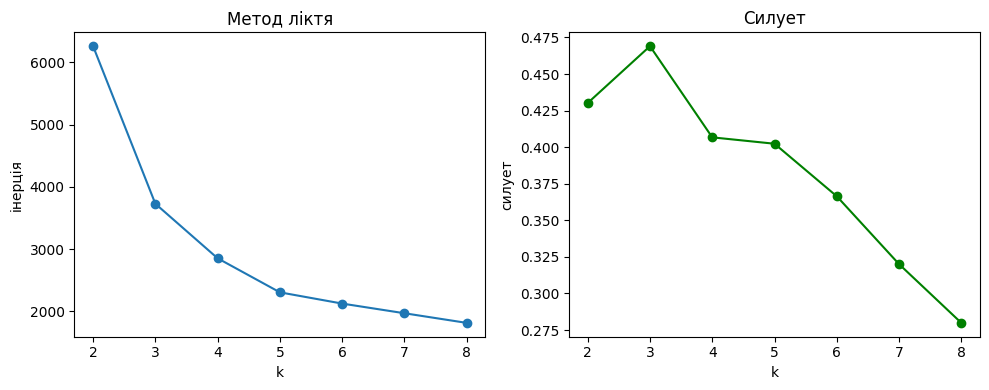

In [ ]:
results_k = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    s = silhouette_score(X, model.labels_)
    results_k.append({"k": k, "inertia": round(model.inertia_, 1), "silhouette": round(s, 4)})

df_k = pd.DataFrame(results_k)
print(df_k.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(df_k["k"], df_k["inertia"], "o-")
axes[0].set_xlabel("k"); axes[0].set_ylabel("інерція"); axes[0].set_title("Метод ліктя")
axes[1].plot(df_k["k"], df_k["silhouette"], "o-", color="green")
axes[1].set_xlabel("k"); axes[1].set_ylabel("силует"); axes[1].set_title("Силует")
plt.tight_layout()
plt.show()

## 5. Ієрархічна кластеризація

Метод Варда починає з окремих абонентів і щоразу об'єднує два кластери. Довгі вертикальні лінії дендрограми — де різати. Довжина розрізу — відстань між злиттями навколо k кластерів.

Довжини розрізів:
  k=3: 29.7452
  k=4: 11.5363
  k=5: 9.5828
  k=6: 3.2014


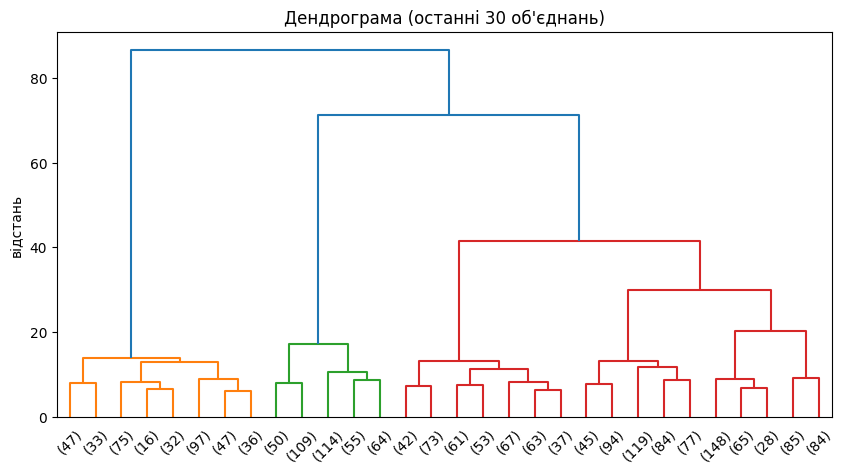

In [ ]:
Z = linkage(X, "ward")

fig, ax = plt.subplots(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax)
ax.set_title("Дендрограма (останні 30 об'єднань)")
ax.set_ylabel("відстань")
plt.tight_layout()
plt.show()

print("Довжини розрізів:")
for k in range(3, 7):
    cut = Z[-(k - 1), 2] - Z[-k, 2]
    print(f"  k={k}: {cut:.4f}")

## 6. Порівняння двох поділів

ARI (adjusted Rand index) показує, наскільки однаково два поділи розкладають абонентів. Від 0.9 — майже однакові. Таблиця спряженості показує, чи кожному кластеру k-середніх відповідає один кластер Варда.

In [ ]:
k = 3  # найкращий силует 0.4690 і найбільший розріз Варда 29.75 при k=3

model_final = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
labels = model_final.labels_

ward_labels = fcluster(Z, k, "maxclust")

print("Таблиця спряженості:")
print(pd.crosstab(labels, ward_labels, rownames=["kmeans"], colnames=["ward"]))
print(f"\nARI = {adjusted_rand_score(labels, ward_labels):.4f}")

Таблиця спряженості:
ward      1    2     3
kmeans                
0         0    0  1224
1       383    0     1
2         0  392     0

ARI = 0.9984


## 7. Профіль сегментів

Сегмент корисний, коли його можна описати одним реченням. Профіль порівнює центри сегментів у вихідних одиницях із середнім усієї бази.

In [ ]:
profile = customers.assign(
    segment=labels,
    ind_1985=customers["meter_type"] == "IND_1985"
)
seg_stats = profile.groupby("segment").agg(
    n=("abonent_id", "count"),
    avg_daily_kwh=("avg_daily_kwh", "mean"),
    night_share=("night_share", "mean"),
    seasonality=("seasonality", "mean"),
    weekend_ratio=("weekend_ratio", "mean"),
    stability=("stability", "mean"),
    churned=("churned", "mean"),
    ind_1985=("ind_1985", "mean"),
).round(4)

base = pd.Series({
    "n": 2000,
    "avg_daily_kwh": round(customers["avg_daily_kwh"].mean(), 4),
    "night_share": round(customers["night_share"].mean(), 4),
    "seasonality": round(customers["seasonality"].mean(), 4),
    "weekend_ratio": round(customers["weekend_ratio"].mean(), 4),
    "stability": round(customers["stability"].mean(), 4),
    "churned": round(customers["churned"].mean(), 4),
    "ind_1985": round((customers["meter_type"] == "IND_1985").mean(), 4),
}, name="уся база")

print(pd.concat([seg_stats, base.to_frame().T]).to_string(float_format="{:.4f}".format))

               n  avg_daily_kwh  night_share  seasonality  weekend_ratio  stability  churned  ind_1985
0         1224.0        19.0817       0.3342       1.6597         1.0635     0.6908   0.1846    0.1266
1          384.0         9.7005       0.1917       0.4517         1.3659     0.5888   0.2917    0.0990
2          392.0        47.0209       0.1295       1.1822         0.6492     0.7658   0.3520    0.0765
уся база  2000.0        22.7566       0.2667       1.3342         1.0403     0.6859   0.2380    0.1115


## 8. Карта Кохонена

Карта Кохонена — сітка нейронів. Схожі абоненти потрапляють у сусідні вузли. Топографічна помилка — частка абонентів, у яких два найближчі нейрони не сусідні на сітці: що менша, то краща карта.

топографічна помилка: sigma = 1.5 — 0.145, sigma = 0.5 — 0.659


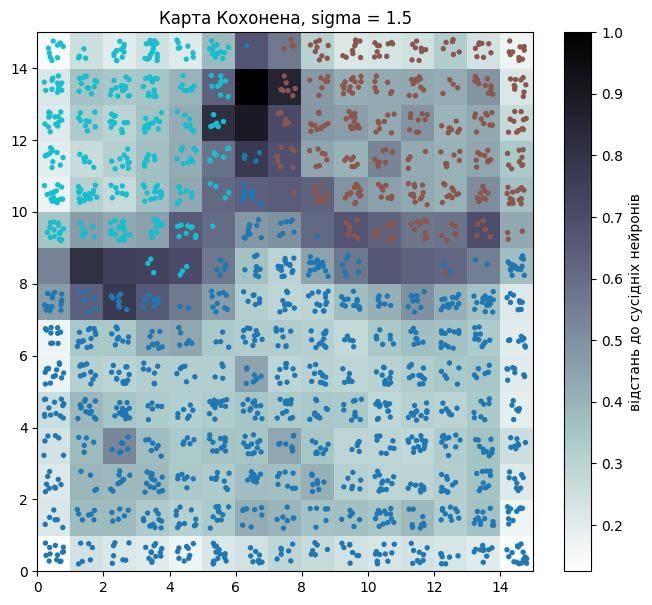

In [ ]:
def train_som(sigma):
    som = MiniSom(15, 15, X.shape[1], sigma=sigma, learning_rate=0.5, random_seed=0)
    som.pca_weights_init(X)
    som.train(X, 20000, random_order=True)
    return som

som = train_som(1.5)
som_small = train_som(0.5)
print(f"топографічна помилка: sigma = 1.5 — {som.topographic_error(X):.3f}, sigma = 0.5 — {som_small.topographic_error(X):.3f}")

winners = np.array([som.winner(x) for x in X]) + 0.5
jitter = np.random.default_rng(0).uniform(-0.3, 0.3, size=winners.shape)
mesh = plt.pcolor(som.distance_map().T, cmap="bone_r")
plt.colorbar(mesh, label="відстань до сусідніх нейронів")
points = plt.scatter(*(winners + jitter).T, c=labels, s=8, cmap="tab10")
plt.legend(*points.legend_elements(), title="сегмент", loc="upper left", bbox_to_anchor=(1.25, 1))
plt.title("Карта Кохонена, sigma = 1.5")
plt.show()

## 9. Асоціативні правила

Правило «A → B»: у кого є A, у того часто є й B. Підтримка — частка абонентів із A і B разом. Достовірність — частка B серед тих, хто має A. Ліфт — у скільки разів достовірність вища за частоту B у базі.

In [ ]:
no_churn = events[events["event_type"] != "churn"]
basket = pd.crosstab(no_churn["abonent_id"], no_churn["event_type"]) > 0
basket = basket.reindex(customers["abonent_id"], fill_value=False)
basket["churned"] = customers["churned"].astype(bool).to_numpy()


def churn_rules(min_support):
    frequent = apriori(basket, min_support=min_support, use_colnames=True)
    rules = association_rules(frequent, num_itemsets=len(basket), metric="confidence", min_threshold=0.3)
    return rules[rules["consequents"] == frozenset({"churned"})].sort_values("lift", ascending=False)


r05 = churn_rules(0.05)
print(f"Правил із наслідком churned при підтримці 0.05: {len(r05)}")
print(r05[["antecedents", "support", "confidence", "lift"]].head(5).to_string(index=False))

r10 = churn_rules(0.10)
print(f"\nПравил із наслідком churned при підтримці 0.10: {len(r10)}")

Правил із наслідком churned при підтримці 0.05: 27
                                  antecedents  support  confidence      lift
       (outage, complaint, payment_delay)   0.0900    0.600000  2.521008
(contract_query, tariff_change, complaint, outage)   0.0515    0.588571  2.472989
 (tariff_change, outage, complaint, payment_delay)   0.0655    0.587444  2.468252
         (tariff_change, complaint, contract_query)   0.0770    0.585551  2.460300
             (tariff_change, outage, payment_delay)   0.0790    0.583026  2.449688

Правил із наслідком churned при підтримці 0.10: 12


## 10. Пастки (T-1, T-2, T-3)

Простий висновок із даних буває хибним. Перевіряємо кожну пастку числами, що порівнюються з порогом.

In [ ]:
# T-1: кореляція voltage_dev_mean і loss_index_mean по всій базі й по районах
r_all = customers["voltage_dev_mean"].corr(customers["loss_index_mean"])
print(f"T-1: по всій базі r = {r_all:.4f}  (поріг |r| > 0.2 → {'ТАК' if abs(r_all) > 0.2 else 'НІ'})")
for d, g in customers.groupby("district"):
    r = g["voltage_dev_mean"].corr(g["loss_index_mean"])
    print(f"  {d}: r = {r:.4f}  (|r| < 0.1 → {'ТАК' if abs(r) < 0.1 else 'НІ'})")

# T-2: seasonality IND_1985 vs решта
ind_seas = customers[customers["meter_type"] == "IND_1985"]["seasonality"].mean()
rest_seas = customers[customers["meter_type"] != "IND_1985"]["seasonality"].mean()
ratio = ind_seas / rest_seas
print(f"\nT-2: IND_1985 seasonality = {ind_seas:.4f}, решта = {rest_seas:.4f}, відношення = {ratio:.4f}")
print(f"  (поріг: < 0.8 або > 1.2 → {'ТАК' if ratio < 0.8 or ratio > 1.2 else 'НІ'})")

# T-3: кореляція avg_price_uah_kwh і churned у top 30% і решті
top600 = customers.nlargest(600, "annual_charge_uah")
rest600 = customers[~customers.index.isin(top600.index)]
r_top = top600["avg_price_uah_kwh"].corr(top600["churned"])
r_rest = rest600["avg_price_uah_kwh"].corr(rest600["churned"])
print(f"\nT-3: top-600 r = {r_top:.4f}, решта r = {r_rest:.4f}")
print(f"  (знаки різні → {'ТАК' if (r_top > 0) != (r_rest > 0) else 'НІ'})")

T-1: по всій базі r = 0.3693  (поріг |r| > 0.2 → ТАК)
  centre: r = -0.0588  (|r| < 0.1 → ТАК)
  north: r = -0.0109  (|r| < 0.1 → ТАК)
  south: r = -0.0368  (|r| < 0.1 → ТАК)
  west: r = -0.0198  (|r| < 0.1 → ТАК)

T-2: IND_1985 seasonality = 1.4083, решта = 1.3249, відношення = 1.0629
  (поріг: < 0.8 або > 1.2 → НІ)

T-3: top-600 r = 0.2997, решта r = 0.1652
  (знаки різні → НІ)


## 11. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [ ]:
x = np.asarray(X)
segments = pd.DataFrame({"abonent_id": customers["abonent_id"], "segment_id": labels})

assert x.shape == (2000, 5), "X має містити 2000 абонентів і 5 ознак із features"
assert np.allclose(x.mean(axis=0), 0) and np.allclose(x.std(axis=0), 1, atol=1e-3), "ознаки X не стандартизовано"
assert np.corrcoef(x[:, 0], np.log(customers["avg_daily_kwh"]))[0, 1] > 0.999, "перша колонка X — не логарифм avg_daily_kwh, або customers змінено чи пересортовано"
assert len(segments) == 2000 and segments["abonent_id"].is_unique, "має бути рядок на кожного з 2000 абонентів"
assert pd.api.types.is_integer_dtype(segments["segment_id"]), "segment_id мають бути цілі числа"
assert 3 <= segments["segment_id"].nunique() <= 6, "сегментів має бути від 3 до 6"

segments.to_csv("segments.csv", index=False)
print("усе гаразд:", segments["segment_id"].value_counts().sort_index().to_dict())

усе гаразд: {0: 1224, 1: 384, 2: 392}
